In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
# Load the dataset
df = pd.read_csv("dataset_12000_records.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (12000, 36)


In [4]:
print(df.head())

  Patient_ID  Age  Gender        BMI Smoking_Status Alcohol_Consumption  \
0   PT_00001   65  Female  25.564766             No                  No   
1   PT_00002   83    Male  30.503110            Yes                 Yes   
2   PT_00003   76    Male  21.934792             No                  No   
3   PT_00004   72  Female  22.048039             No                 Yes   
4   PT_00005   54    Male  27.102739             No                  No   

   Exercise_Frequency  Hypertension  Diabetes  Chronic_Kidney_Disease  ...  \
0                   0             1         0                       0  ...   
1                   1             1         1                       1  ...   
2                   0             1         1                       1  ...   
3                   0             0         1                       0  ...   
4                   3             0         0                       0  ...   

   Blood_Glucose         BNP  Length_of_Stay  ICU_Admission  \
0      95.586026 

In [5]:
print(df.tail())

      Patient_ID  Age  Gender        BMI Smoking_Status Alcohol_Consumption  \
11995   PT_11996   38  Female  26.447694             No                  No   
11996   PT_11997   87  Female  31.303370             No                 Yes   
11997   PT_11998   62    Male  35.160424            Yes                  No   
11998   PT_11999   85    Male  28.831126             No                  No   
11999   PT_12000   68    Male  30.701425            Yes                  No   

       Exercise_Frequency  Hypertension  Diabetes  Chronic_Kidney_Disease  \
11995                   2             1         0                       0   
11996                   1             0         0                       1   
11997                   1             1         0                       0   
11998                   2             1         1                       0   
11999                   0             0         0                       1   

       ...  Blood_Glucose         BNP  Length_of_Stay  ICU_Adm

In [6]:
print(df.shape)

(12000, 36)


In [7]:
df.columns.tolist()

['Patient_ID',
 'Age',
 'Gender',
 'BMI',
 'Smoking_Status',
 'Alcohol_Consumption',
 'Exercise_Frequency',
 'Hypertension',
 'Diabetes',
 'Chronic_Kidney_Disease',
 'Coronary_Artery_Disease',
 'Previous_Stroke',
 'Atrial_Fibrillation',
 'Previous_HF_Admissions',
 'Previous_Hospital_Admissions',
 'Heart_Failure_Type',
 'NYHA_Class',
 'Ejection_Fraction',
 'Systolic_BP',
 'Diastolic_BP',
 'Heart_Rate',
 'Oxygen_Saturation',
 'Creatinine',
 'Sodium',
 'Potassium',
 'Hemoglobin',
 'Blood_Glucose',
 'BNP',
 'Length_of_Stay',
 'ICU_Admission',
 'Emergency_Admission',
 'Beta_Blocker',
 'ACE_ARB',
 'Diuretic',
 'SGLT2_Inhibitor',
 'Readmitted_30_Days']

In [8]:
print(df.columns.tolist())

['Patient_ID', 'Age', 'Gender', 'BMI', 'Smoking_Status', 'Alcohol_Consumption', 'Exercise_Frequency', 'Hypertension', 'Diabetes', 'Chronic_Kidney_Disease', 'Coronary_Artery_Disease', 'Previous_Stroke', 'Atrial_Fibrillation', 'Previous_HF_Admissions', 'Previous_Hospital_Admissions', 'Heart_Failure_Type', 'NYHA_Class', 'Ejection_Fraction', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Oxygen_Saturation', 'Creatinine', 'Sodium', 'Potassium', 'Hemoglobin', 'Blood_Glucose', 'BNP', 'Length_of_Stay', 'ICU_Admission', 'Emergency_Admission', 'Beta_Blocker', 'ACE_ARB', 'Diuretic', 'SGLT2_Inhibitor', 'Readmitted_30_Days']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 36 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Patient_ID                    12000 non-null  object 
 1   Age                           12000 non-null  int64  
 2   Gender                        12000 non-null  object 
 3   BMI                           12000 non-null  float64
 4   Smoking_Status                12000 non-null  object 
 5   Alcohol_Consumption           12000 non-null  object 
 6   Exercise_Frequency            12000 non-null  int64  
 7   Hypertension                  12000 non-null  int64  
 8   Diabetes                      12000 non-null  int64  
 9   Chronic_Kidney_Disease        12000 non-null  int64  
 10  Coronary_Artery_Disease       12000 non-null  int64  
 11  Previous_Stroke               12000 non-null  int64  
 12  Atrial_Fibrillation           12000 non-null  int64  
 13  P

In [10]:
df.describe()

,Age,BMI,Exercise_Frequency,Hypertension,Diabetes,Chronic_Kidney_Disease,Coronary_Artery_Disease,Previous_Stroke,Atrial_Fibrillation,Previous_HF_Admissions,...,Blood_Glucose,BNP,Length_of_Stay,ICU_Admission,Emergency_Admission,Beta_Blocker,ACE_ARB,Diuretic,SGLT2_Inhibitor,Readmitted_30_Days
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,...,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,67.396417,27.790903,1.018583,0.412417,0.296667,0.268000,0.401500,0.183083,0.277333,0.631083,...,118.077890,204.936134,8.146667,0.339917,0.511667,0.804167,0.762000,0.576667,0.395000,0.300000
std,13.079380,5.035375,1.036819,0.492290,0.456807,0.442936,0.490222,0.386751,0.447701,0.874765,...,32.696853,203.739039,6.472865,0.473700,0.499885,0.396857,0.425877,0.494108,0.488871,0.458277
min,30.000000,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,70.000000,50.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.000000,24.299963,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,92.609403,84.818008,3.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000
50%,68.000000,27.780840,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,115.999968,142.847005,6.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
75%,77.000000,31.246772,2.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,...,139.825765,248.264021,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,95.000000,45.975566,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000,...,258.524090,4097.436155,30.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
#Checking for missing values
missing_values = df.isnull().sum()

print(missing_values)

Patient_ID                      0
Age                             0
Gender                          0
BMI                             0
Smoking_Status                  0
Alcohol_Consumption             0
Exercise_Frequency              0
Hypertension                    0
Diabetes                        0
Chronic_Kidney_Disease          0
Coronary_Artery_Disease         0
Previous_Stroke                 0
Atrial_Fibrillation             0
Previous_HF_Admissions          0
Previous_Hospital_Admissions    0
Heart_Failure_Type              0
NYHA_Class                      0
Ejection_Fraction               0
Systolic_BP                     0
Diastolic_BP                    0
Heart_Rate                      0
Oxygen_Saturation               0
Creatinine                      0
Sodium                          0
Potassium                       0
Hemoglobin                      0
Blood_Glucose                   0
BNP                             0
Length_of_Stay                  0
ICU_Admission 

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage
})

print(missing_table)

                              Missing Values  Percentage
Patient_ID                                 0         0.0
Age                                        0         0.0
Gender                                     0         0.0
BMI                                        0         0.0
Smoking_Status                             0         0.0
Alcohol_Consumption                        0         0.0
Exercise_Frequency                         0         0.0
Hypertension                               0         0.0
Diabetes                                   0         0.0
Chronic_Kidney_Disease                     0         0.0
Coronary_Artery_Disease                    0         0.0
Previous_Stroke                            0         0.0
Atrial_Fibrillation                        0         0.0
Previous_HF_Admissions                     0         0.0
Previous_Hospital_Admissions               0         0.0
Heart_Failure_Type                         0         0.0
NYHA_Class                     

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
print("Duplicate Patient IDs:", df["Patient_ID"].duplicated().sum())

Duplicate Patient IDs: 0


In [15]:
target = "Readmitted_30_Days"

print(df[target].value_counts())

Readmitted_30_Days
0    8400
1    3600
Name: count, dtype: int64


In [16]:
print(df[target].value_counts(normalize=True) * 100)

Readmitted_30_Days
0    70.0
1    30.0
Name: proportion, dtype: float64


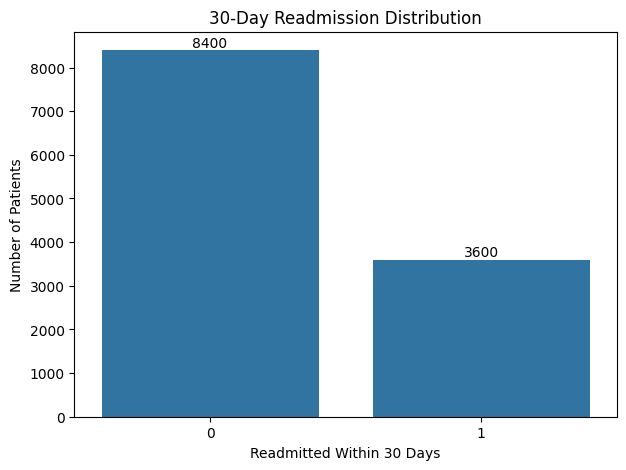

In [17]:
#Visualizing the target variable distribution
plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=df,
    x="Readmitted_30_Days"
)

plt.title("30-Day Readmission Distribution")
plt.xlabel("Readmitted Within 30 Days")
plt.ylabel("Number of Patients")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

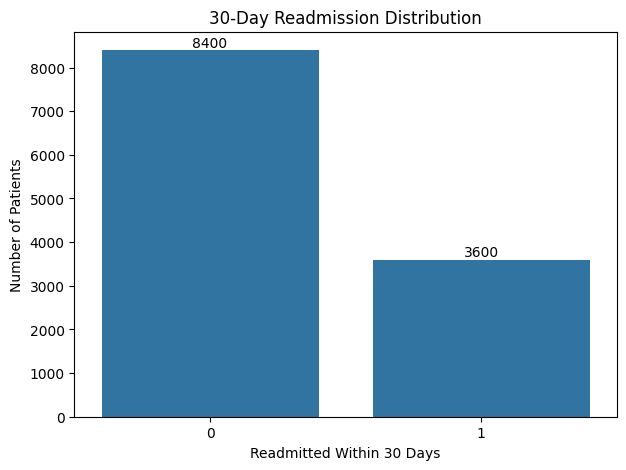

In [18]:
#Class balance check
plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=df,
    x="Readmitted_30_Days"
)

plt.title("30-Day Readmission Distribution")
plt.xlabel("Readmitted Within 30 Days")
plt.ylabel("Number of Patients")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [19]:
#Check categorical columns
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
Index(['Patient_ID', 'Gender', 'Smoking_Status', 'Alcohol_Consumption',
       'Heart_Failure_Type'],
      dtype='object')


In [20]:
# Numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical columns:")
print(numerical_columns)

Numerical columns:
Index(['Age', 'BMI', 'Exercise_Frequency', 'Hypertension', 'Diabetes',
       'Chronic_Kidney_Disease', 'Coronary_Artery_Disease', 'Previous_Stroke',
       'Atrial_Fibrillation', 'Previous_HF_Admissions',
       'Previous_Hospital_Admissions', 'NYHA_Class', 'Ejection_Fraction',
       'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Oxygen_Saturation',
       'Creatinine', 'Sodium', 'Potassium', 'Hemoglobin', 'Blood_Glucose',
       'BNP', 'Length_of_Stay', 'ICU_Admission', 'Emergency_Admission',
       'Beta_Blocker', 'ACE_ARB', 'Diuretic', 'SGLT2_Inhibitor',
       'Readmitted_30_Days'],
      dtype='object')


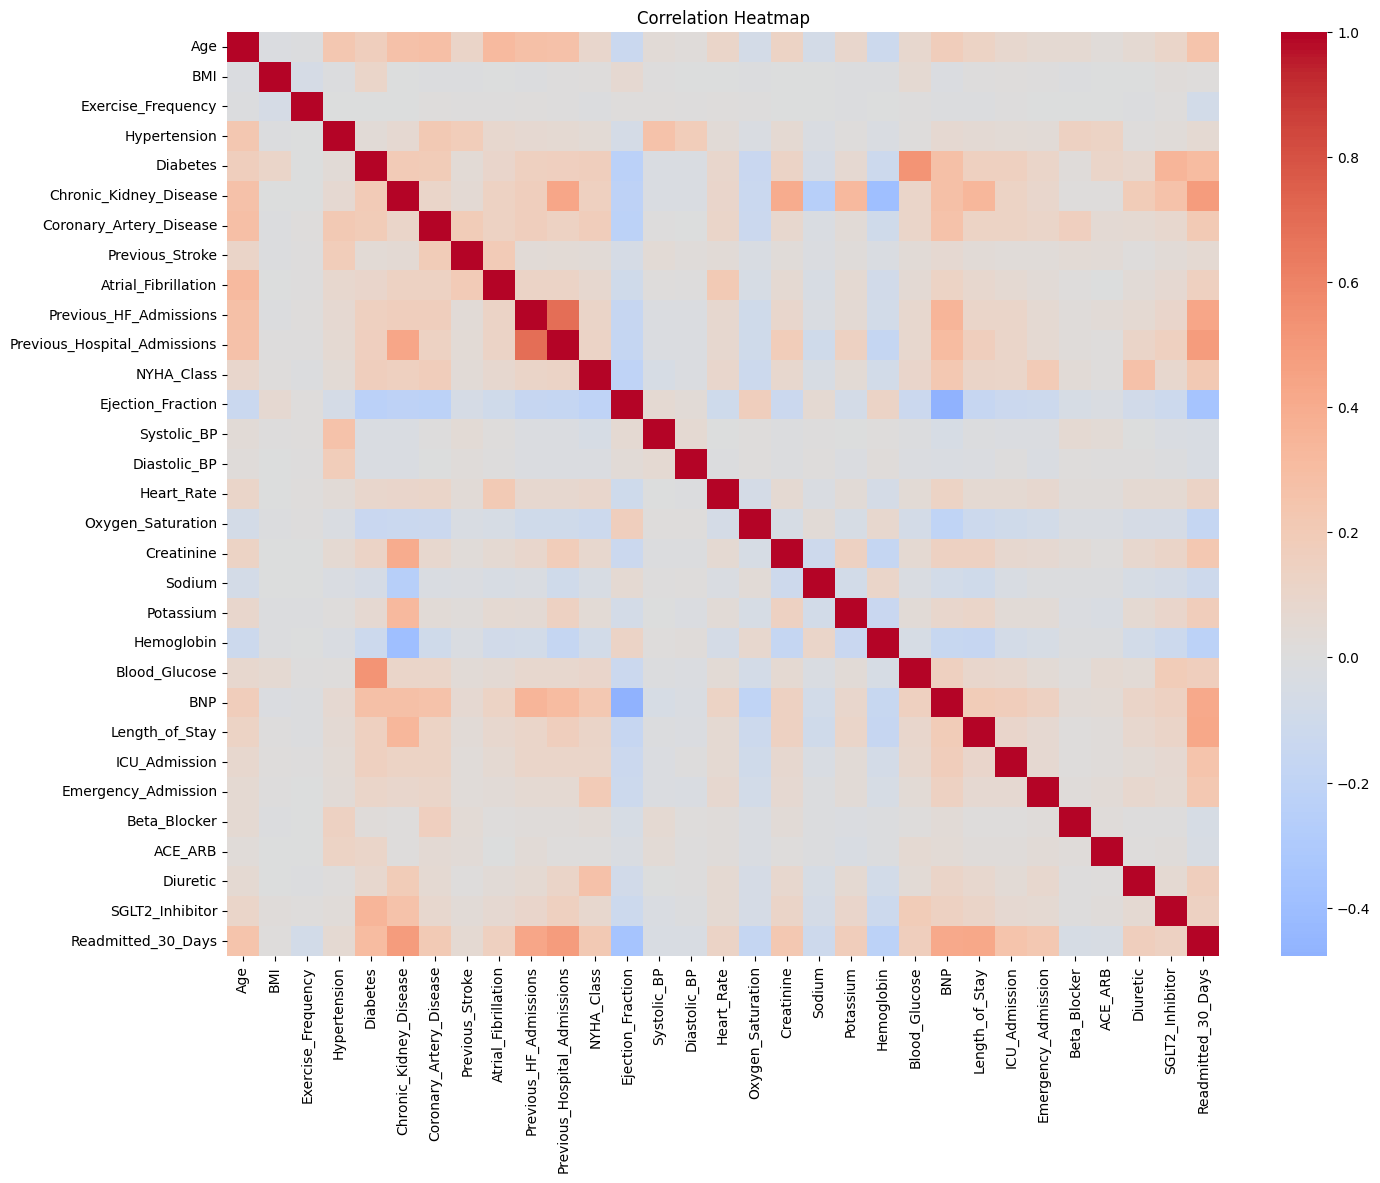

In [21]:
#Data leakage check
correlation = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(16,12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

In [22]:
df = df.drop(columns=["Patient_ID"])

In [23]:
X = df.drop(columns=["Readmitted_30_Days"])
y = df["Readmitted_30_Days"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12000, 34)
y shape: (12000,)


In [24]:
#identifying categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Gender', 'Smoking_Status', 'Alcohol_Consumption', 'Heart_Failure_Type']

Numerical features:
['Age', 'BMI', 'Exercise_Frequency', 'Hypertension', 'Diabetes', 'Chronic_Kidney_Disease', 'Coronary_Artery_Disease', 'Previous_Stroke', 'Atrial_Fibrillation', 'Previous_HF_Admissions', 'Previous_Hospital_Admissions', 'NYHA_Class', 'Ejection_Fraction', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Oxygen_Saturation', 'Creatinine', 'Sodium', 'Potassium', 'Hemoglobin', 'Blood_Glucose', 'BNP', 'Length_of_Stay', 'ICU_Admission', 'Emergency_Admission', 'Beta_Blocker', 'ACE_ARB', 'Diuretic', 'SGLT2_Inhibitor']


In [25]:
#Train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9600, 34)
Testing data: (2400, 34)


In [26]:
#Creating preprocessing pipelines for numerical and categorical features
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [28]:
#Logiastic regression 
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [29]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [30]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [31]:
#Evaluating the logistic regression model
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression")
print("----------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)
print("ROC-AUC  :", lr_auc)

Logistic Regression
----------------------
Accuracy : 0.895
Precision: 0.8524096385542169
Recall   : 0.7861111111111111
F1 Score : 0.8179190751445087
ROC-AUC  : 0.9561871693121693


In [32]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.91      0.94      0.93      1680
           1       0.85      0.79      0.82       720

    accuracy                           0.90      2400
   macro avg       0.88      0.86      0.87      2400
weighted avg       0.89      0.90      0.89      2400



In [33]:
#Knn model
KNeighborsClassifier(n_neighbors=5)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [34]:
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]
)

In [35]:
knn_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [37]:
y_pred_knn = knn_model.predict(X_test)

y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

In [38]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)
knn_auc = roc_auc_score(y_test, y_prob_knn)

print("KNN")
print("----------------------")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1 Score :", knn_f1)
print("ROC-AUC  :", knn_auc)

KNN
----------------------
Accuracy : 0.8416666666666667
Precision: 0.8231939163498099
Recall   : 0.6013888888888889
F1 Score : 0.695024077046549
ROC-AUC  : 0.8877831514550264


In [39]:
# Select the best k for KNN using GridSearchCV
k_values = [3, 5, 7, 9, 11, 15, 21]

knn_results = []

for k in k_values:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", KNeighborsClassifier(
                n_neighbors=k
            ))
        ]
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    knn_results.append({
        "k": k,
        "Mean F1": scores.mean()
    })

knn_results_df = pd.DataFrame(knn_results)

print(knn_results_df)

    k   Mean F1
0   3  0.688915
1   5  0.695679
2   7  0.704466
3   9  0.700403
4  11  0.695333
5  15  0.693018
6  21  0.692783


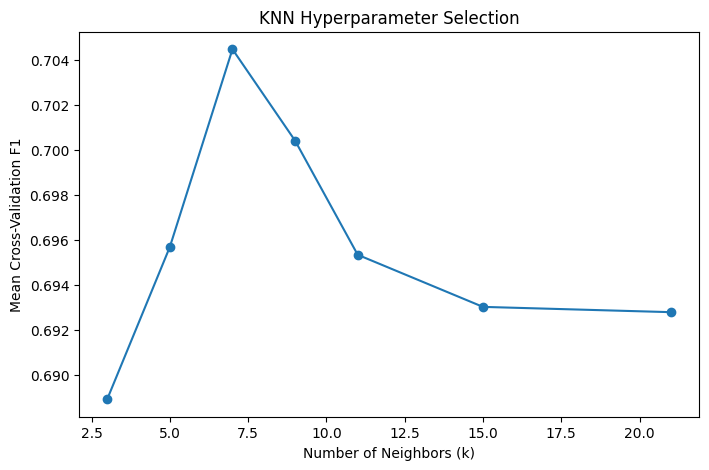

In [40]:
plt.figure(figsize=(8,5))

plt.plot(
    knn_results_df["k"],
    knn_results_df["Mean F1"],
    marker="o"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean Cross-Validation F1")
plt.title("KNN Hyperparameter Selection")

plt.show()

In [41]:
best_k = knn_results_df.loc[
    knn_results_df["Mean F1"].idxmax(),
    "k"
]

print("Best k:", best_k)

Best k: 7


In [ ]:
#Training the KNN
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=int(best_k)
        ))
    ]
)

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

In [43]:
#Decision Tree model
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42
        ))
    ]
)

In [44]:
#Train
tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [45]:
#Predictions
y_pred_tree = tree_model.predict(X_test)

y_prob_tree = tree_model.predict_proba(X_test)[:, 1]

In [46]:
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(y_test, y_pred_tree)
tree_recall = recall_score(y_test, y_pred_tree)
tree_f1 = f1_score(y_test, y_pred_tree)
tree_auc = roc_auc_score(y_test, y_prob_tree)

print("Decision Tree")
print("----------------------")
print("Accuracy :", tree_accuracy)
print("Precision:", tree_precision)
print("Recall   :", tree_recall)
print("F1 Score :", tree_f1)
print("ROC-AUC  :", tree_auc)

Decision Tree
----------------------
Accuracy : 0.8383333333333334
Precision: 0.7577639751552795
Recall   : 0.6777777777777778
F1 Score : 0.7155425219941349
ROC-AUC  : 0.8907415674603175


In [47]:
#Decision Tree Hyperparameter Experiment
depth_values = [2, 3, 4, 5, 6, 8, 10, None]

tree_results = []

for depth in depth_values:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=depth,
                min_samples_split=10,
                min_samples_leaf=5,
                random_state=42
            ))
        ]
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    tree_results.append({
        "Max Depth": depth,
        "Mean F1": scores.mean()
    })

tree_results_df = pd.DataFrame(tree_results)

print(tree_results_df)

   Max Depth   Mean F1
0        2.0  0.639940
1        3.0  0.671384
2        4.0  0.695754
3        5.0  0.690569
4        6.0  0.707347
5        8.0  0.697497
6       10.0  0.687517
7        NaN  0.678945


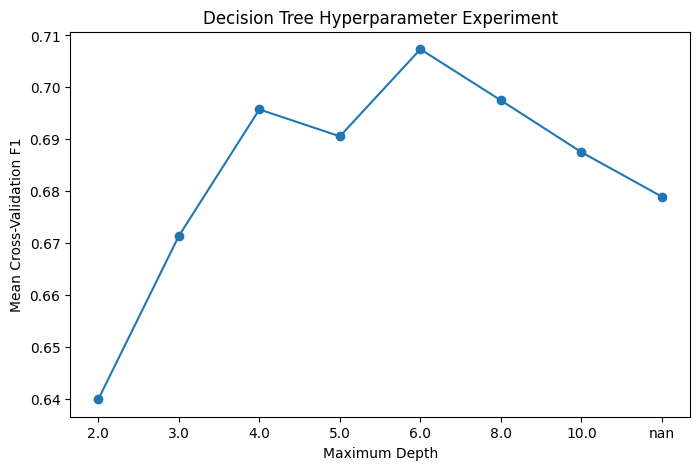

In [48]:
plt.figure(figsize=(8,5))

plt.plot(
    tree_results_df["Max Depth"].astype(str),
    tree_results_df["Mean F1"],
    marker="o"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Mean Cross-Validation F1")
plt.title("Decision Tree Hyperparameter Experiment")

plt.show()

In [51]:
#Create General Evaluation Function
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    return results, predictions, probabilities

In [52]:
#Evalutte all three Models
lr_results, y_pred_lr, y_prob_lr = evaluate_model(
    logistic_model,
    X_test,
    y_test
)

knn_results, y_pred_knn, y_prob_knn = evaluate_model(
    knn_model,
    X_test,
    y_test
)

tree_results, y_pred_tree, y_prob_tree = evaluate_model(
    tree_model,
    X_test,
    y_test
)

In [53]:
#Crete Mandatory Comparison Table
train_acc_lr = logistic_model.score(X_train, y_train)
train_acc_knn = knn_model.score(X_train, y_train)
train_acc_tree = tree_model.score(X_train, y_train)

In [55]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree"
    ],

    "Train Accuracy": [
        train_acc_lr,
        train_acc_knn,
        train_acc_tree
    ],

    "Test Accuracy": [
        lr_results["Accuracy"],
        knn_results["Accuracy"],
        tree_results["Accuracy"]
    ],

    "Precision": [
        lr_results["Precision"],
        knn_results["Precision"],
        tree_results["Precision"]
    ],

    "Recall": [
        lr_results["Recall"],
        knn_results["Recall"],
        tree_results["Recall"]
    ],

    "F1 Score": [
        lr_results["F1 Score"],
        knn_results["F1 Score"],
        tree_results["F1 Score"]
    ],

    "ROC-AUC": [
        lr_results["ROC-AUC"],
        knn_results["ROC-AUC"],
        tree_results["ROC-AUC"]
    ]
})

print(comparison.round(4))

                 Model  Train Accuracy  Test Accuracy  Precision  Recall  \
0  Logistic Regression          0.8946         0.8950     0.8524  0.7861   
1                  KNN          0.8833         0.8475     0.8404  0.6069   
2        Decision Tree          0.8511         0.8383     0.7578  0.6778   

   F1 Score  ROC-AUC  
0    0.8179   0.9562  
1    0.7048   0.8981  
2    0.7155   0.8907  


In [56]:
#Calculate generalization gap
comparison["Accuracy Gap"] = (
    comparison["Train Accuracy"] -
    comparison["Test Accuracy"]
)

print(comparison.round(4))

                 Model  Train Accuracy  Test Accuracy  Precision  Recall  \
0  Logistic Regression          0.8946         0.8950     0.8524  0.7861   
1                  KNN          0.8833         0.8475     0.8404  0.6069   
2        Decision Tree          0.8511         0.8383     0.7578  0.6778   

   F1 Score  ROC-AUC  Accuracy Gap  
0    0.8179   0.9562       -0.0004  
1    0.7048   0.8981        0.0358  
2    0.7155   0.8907        0.0128  


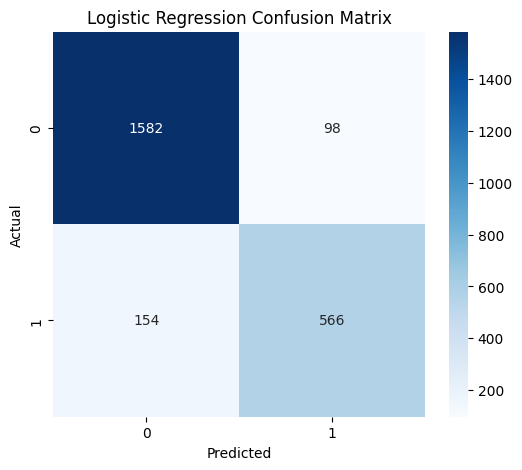

In [ ]:
#Confusion Matrix: Logistic Regression
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

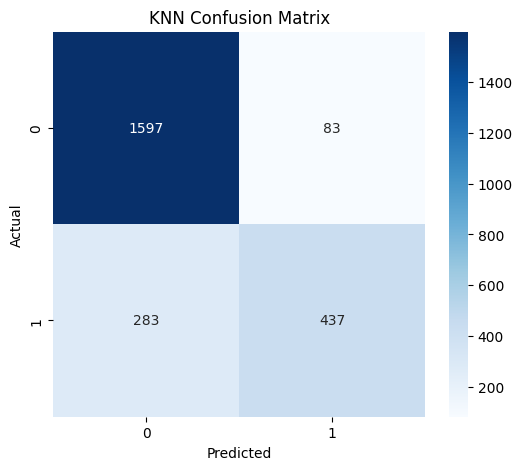

In [ ]:
#Confusion Matrix: KNN
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

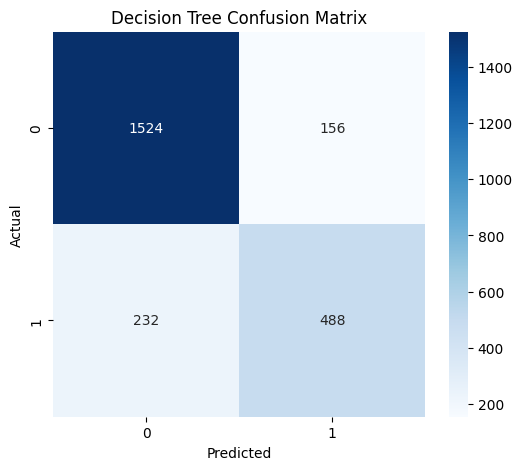

In [59]:
#Confusion matrix: Decision Tree
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

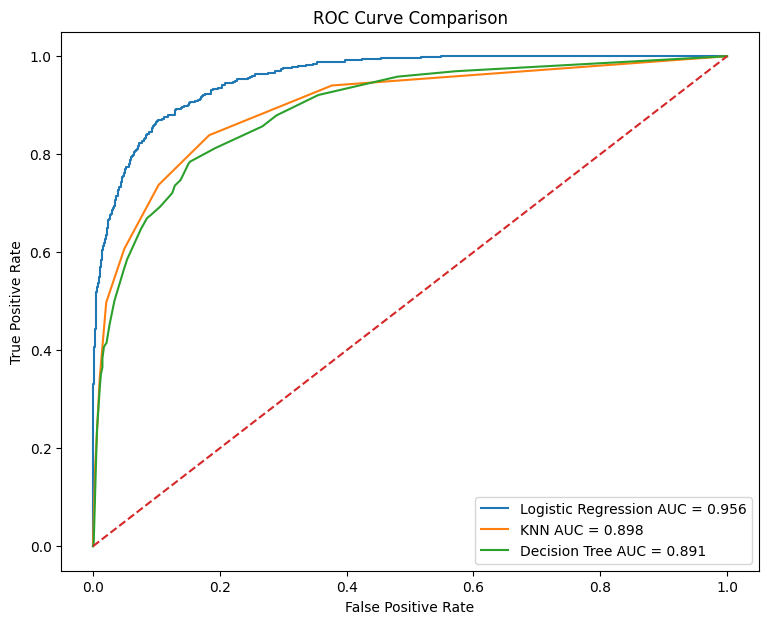

In [61]:
#Plot ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_prob_lr
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test,
    y_prob_knn
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    y_prob_tree
)

plt.figure(figsize=(9,7))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression AUC = {lr_results['ROC-AUC']:.3f}"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN AUC = {knn_results['ROC-AUC']:.3f}"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Decision Tree AUC = {tree_results['ROC-AUC']:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

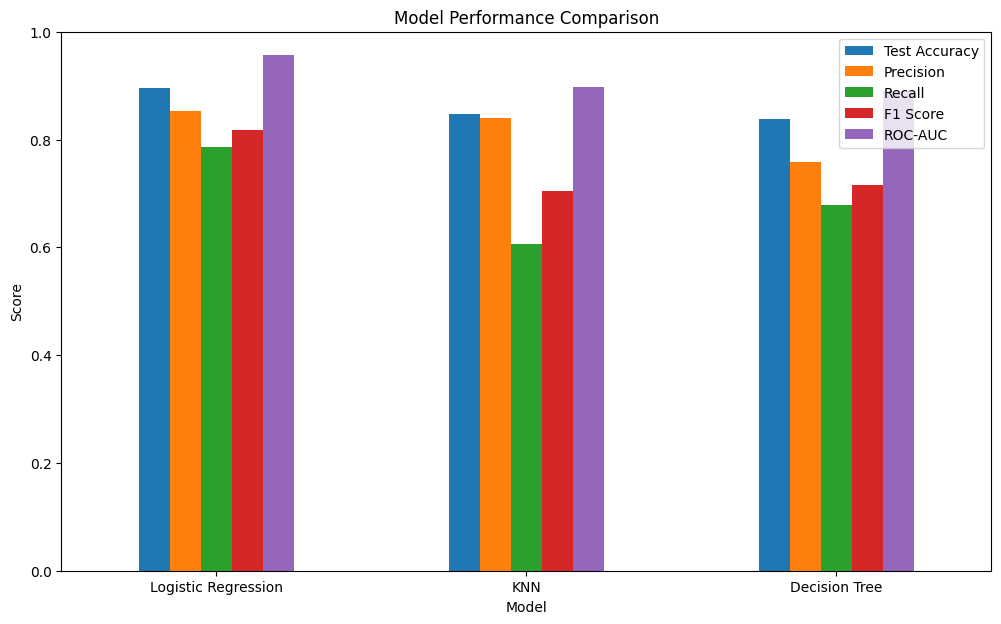

In [62]:
#Matrix Comparison Chart
metrics = [
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_plot = comparison.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12,7)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend()

plt.show()

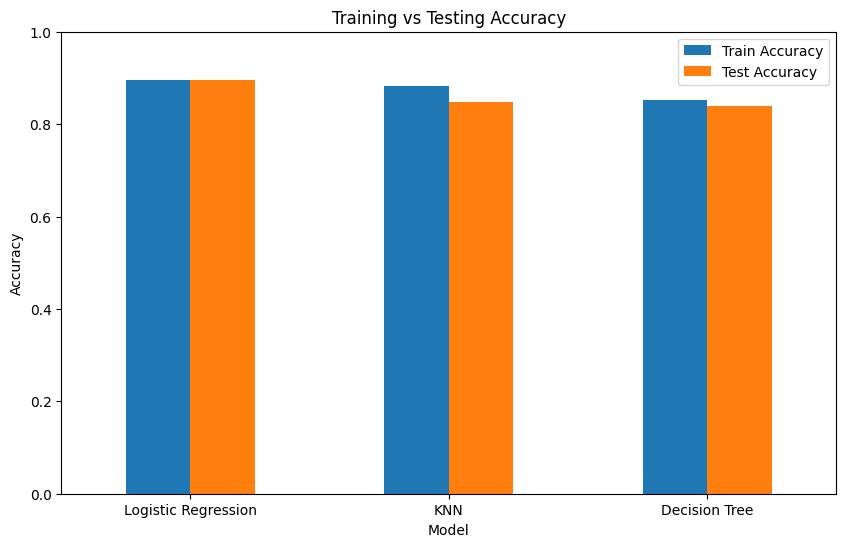

In [63]:
#Training vs Testing Performance
train_test_plot = comparison[
    ["Model", "Train Accuracy", "Test Accuracy"]
].set_index("Model")

train_test_plot.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Training vs Testing Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0,1)

plt.xticks(rotation=0)
plt.show()

In [64]:
#Automatic fit Diagnosis
def diagnose_fit(train_score, test_score):

    gap = train_score - test_score

    if gap > 0.10:
        return "Possible Overfitting"

    elif train_score < 0.70 and test_score < 0.70:
        return "Possible Underfitting"

    else:
        return "Reasonable Generalization"

In [65]:
comparison["Fit Diagnosis"] = comparison.apply(
    lambda row: diagnose_fit(
        row["Train Accuracy"],
        row["Test Accuracy"]
    ),
    axis=1
)

print(comparison.round(4))

                 Model  Train Accuracy  Test Accuracy  Precision  Recall  \
0  Logistic Regression          0.8946         0.8950     0.8524  0.7861   
1                  KNN          0.8833         0.8475     0.8404  0.6069   
2        Decision Tree          0.8511         0.8383     0.7578  0.6778   

   F1 Score  ROC-AUC  Accuracy Gap              Fit Diagnosis  
0    0.8179   0.9562       -0.0004  Reasonable Generalization  
1    0.7048   0.8981        0.0358  Reasonable Generalization  
2    0.7155   0.8907        0.0128  Reasonable Generalization  


In [66]:
#Hyperparameter Tuning for Logistic Regression
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

param_grid_lr = {
    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

grid_lr = GridSearchCV(
    logistic_pipeline,
    param_grid_lr,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Best Parameters:")
print(grid_lr.best_params_)

print("Best CV F1:")
print(grid_lr.best_score_)

Best Parameters:
{'classifier__C': 10}
Best CV F1:
0.8142114498129012


In [67]:
#Final logistic regression model with best parameters
best_logistic_model = grid_lr.best_estimator_

y_pred_lr = best_logistic_model.predict(X_test)

y_prob_lr = best_logistic_model.predict_proba(X_test)[:,1]

In [68]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr))

print("Recall:",
      recall_score(y_test, y_pred_lr))

print("F1:",
      f1_score(y_test, y_pred_lr))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

Accuracy: 0.895
Precision: 0.8524096385542169
Recall: 0.7861111111111111
F1: 0.8179190751445087
ROC-AUC: 0.9561780753968253


In [69]:
#optional class-imbbalance experiment
class_weight="balanced"

In [70]:
balanced_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

balanced_tree.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [71]:
comparison.to_csv(
    "model_comparison.csv",
    index=False
)

In [72]:
predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Logistic_Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Decision_Tree": y_pred_tree
})

predictions.to_csv(
    "model_predictions.csv",
    index=False
)

In [74]:
#Save trained models using joblib
import joblib

joblib.dump(
    best_logistic_model,
    "model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [75]:
joblib.dump(
    knn_model,
    "model.pkl"
)

['model.pkl']

In [76]:
joblib.dump(
    tree_model,
    "model.pkl"
)

['model.pkl']

In [77]:
Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(...))
    ]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme